# Project 1 – Pass-11


## Problem Definition



Business problem: Predict whether a customer will make a successfull transaction,

Data Science problem: This is a supervised learning and classification problem. I will use the Gaussian Naive Bayes model





## Data Collection

### Imports

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from google.colab import userdata
import os

from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn import datasets, metrics, model_selection

## Read parquet from Hugging Face


In [4]:
os.environ["HF_ACCOUNT"] = userdata.get('hf_account')
hf_account = os.environ["HF_ACCOUNT"]
hf_account


'hmsealy'

In [5]:
hf_repo = "Data_Science-22"
os.environ["HF_REPO"] = hf_repo
hf_repo


'Data_Science-22'

In [6]:
# Construct the base Hugging Face URL for your dataset files
hf_url = f"https://huggingface.co/datasets/{hf_account}/{hf_repo}/resolve/main/transactions.parquet"
hf_url


'https://huggingface.co/datasets/hmsealy/Data_Science-22/resolve/main/transactions.parquet'

In [7]:
df3 = pd.read_parquet( hf_url )
df3.shape


(180000, 51)

In [8]:
transaction_df_target_clean = df3


## Recommendations for Data Cleaning

**1. Identifier Columns**
- **Two columns:** `Unnamed: 0` is row numbers and `ID_code` is customer ID. cannot help predict anything
- **Recommendation:** Drop both columns.

**2. Null values:** he `target` column has rows with null values, and some feature columns did too.
- After removing rows with no target, I checked the null percentage of every column: 51 feature columns are 100% null and 0 columns are partly null.
- **Recommendation:** Remove every column that has any missing values.

**3. Target nulls:** 82% null values, rows with nulls are dropped are 100% empty. They have no data to learn from, and nothing to average for imputing.
- **Recommendation:** Drop these rows.

**4. Feature columns with high null counts:** All 51 columns with nulls

**5. Medium null counts:** None. No colum falls between low and high

**6. Low null counts:** None. No column has a small number

**7. Null rows:** After droping the empty columns,no nulls remain


## Exploratory Data Analysis ##

### Normal distribution of features:histogram

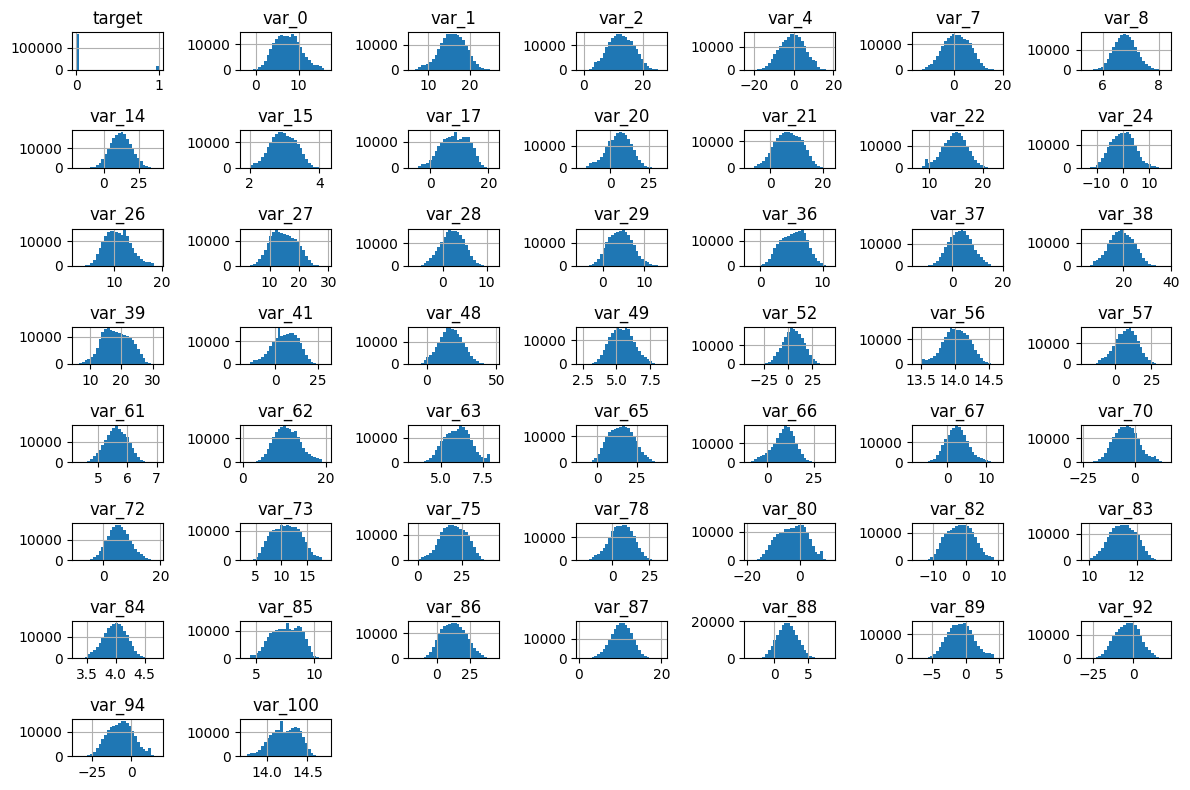

In [9]:
# Display a histogram

transaction_df_target_clean.hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()


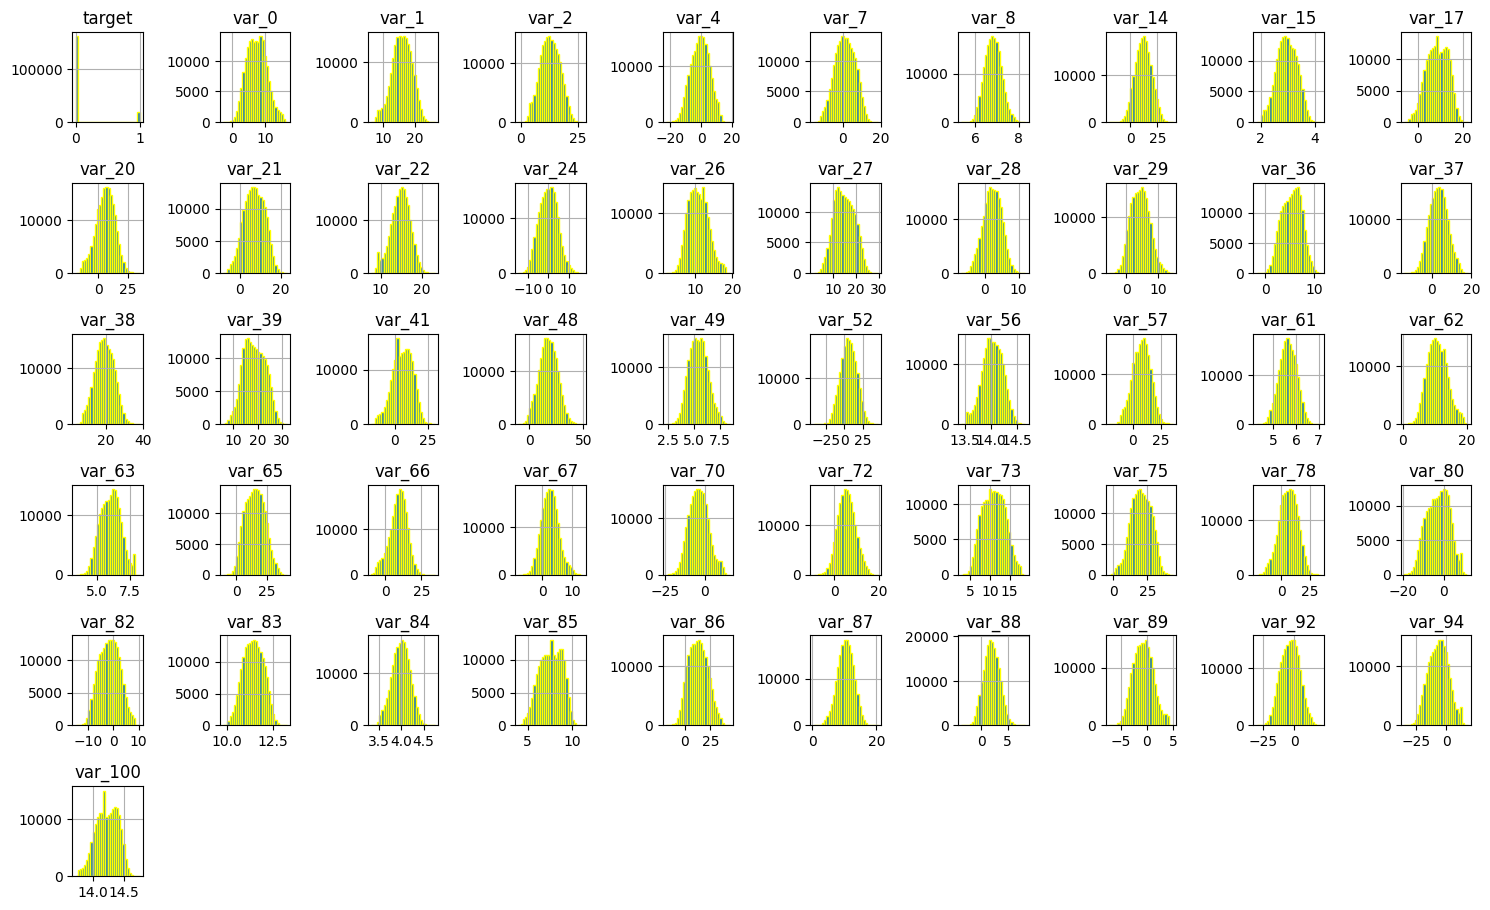

In [ ]:
# Check the distributions of the features

transaction_df_target_clean.hist(
  figsize=(15,15), # size of the whole picture in inches(width,height)
  layout=(10,10),    # 5 rows, 4 column= 20 boxes
  bins=30,         # more bars, so the shape is clear
  edgecolor= "yellow"
)
plt.tight_layout()
plt.show()
#output- each graph look like a bell-shaped (first GNB assumption)

### Independence of features: Correlation matrix

In [ ]:
# Calculate a correlation matrix (target & features)
transaction_df_target_clean.corr()

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
target,1.000000,0.045506,-0.051718,-0.046433,0.041593,-0.041987,0.052457,0.045281,-0.057373,-0.054375,...,-0.052324,-0.053733,-0.042073,0.047543,-0.063871,-0.042765,0.059306,0.040520,0.049072,-0.047005
var_0,0.045506,1.000000,-0.000892,-0.000225,-0.000269,-0.001320,0.002949,0.002901,-0.007758,-0.002799,...,-0.004960,-0.005451,-0.000716,0.004577,-0.004664,-0.001088,0.000236,0.001668,0.001837,0.001475
var_1,-0.051718,-0.000892,1.000000,0.006064,-0.000821,0.000783,-0.007127,-0.006180,-0.002585,-0.001663,...,0.004265,0.002411,0.001484,-0.003859,-0.000485,0.003141,-0.006188,0.000071,-0.003682,0.003964
var_2,-0.046433,-0.000225,0.006064,1.000000,-0.003427,-0.000108,-0.001809,-0.002786,-0.001177,0.006360,...,0.004890,0.002240,0.001980,-0.001161,0.003921,0.002087,-0.004422,-0.003418,-0.001565,0.002418
var_4,0.041593,-0.000269,-0.000821,-0.003427,1.000000,-0.002750,0.003347,0.001377,-0.004732,-0.001814,...,0.000657,-0.005267,-0.004266,-0.004179,-0.004211,-0.002330,0.000254,0.001090,-0.000468,-0.002807
var_7,-0.041987,-0.001320,0.000783,-0.000108,-0.002750,1.000000,-0.003199,-0.003588,0.002329,0.004282,...,-0.000412,0.003262,0.002574,-0.001824,0.001186,0.002811,0.001306,0.000236,-0.000568,0.004575
var_8,0.052457,0.002949,-0.007127,-0.001809,0.003347,-0.003199,1.000000,0.003472,-0.003858,-0.002727,...,-0.008394,-0.004254,-0.002446,0.001117,-0.003713,-0.003929,0.003837,0.003422,0.003204,0.000821
var_14,0.045281,0.002901,-0.006180,-0.002786,0.001377,-0.003588,0.003472,1.000000,-0.007115,-0.004249,...,-0.002214,-0.002179,-0.003054,-0.000160,-0.000504,-0.004046,0.003136,0.005715,0.001501,-0.000106
var_15,-0.057373,-0.007758,-0.002585,-0.001177,-0.004732,0.002329,-0.003858,-0.007115,1.000000,0.002467,...,0.000581,0.006633,0.004569,-0.001573,0.003251,0.003066,-0.001541,-0.003719,-0.002825,0.004247
var_17,-0.054375,-0.002799,-0.001663,0.006360,-0.001814,0.004282,-0.002727,-0.004249,0.002467,1.000000,...,0.005578,0.001237,0.000210,-0.002714,0.004149,-0.002182,-0.002642,-0.001968,-0.004100,-0.000822


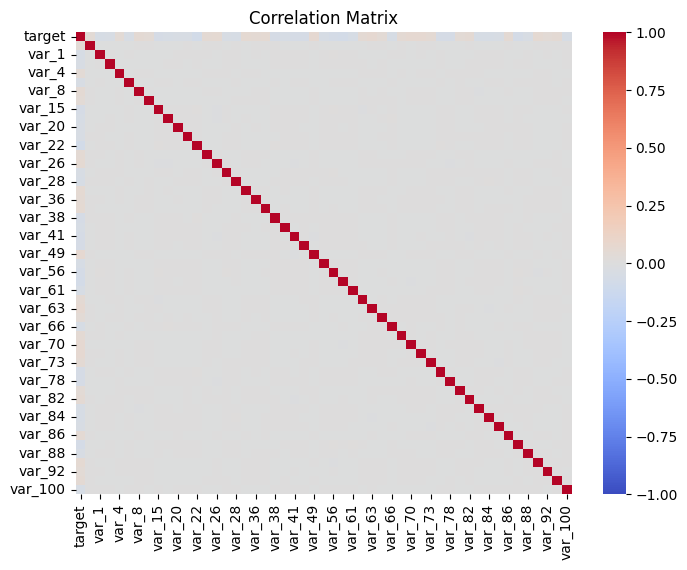

In [ ]:
# Display the correlation matrix

plt.figure(figsize=(8, 6))
sns.heatmap(transaction_df_target_clean.corr(),
            annot=False,
            cmap='coolwarm',  # blue = negative, red = positive
            center=0,         # white = no correlation
            vmin=-1, vmax=1)  # full correlation range
plt.title('Correlation Matrix')
plt.show()


In [ ]:
# select the features
feature_cols =[] #start with an empty list to hold the features
for col in transaction_df_target_clean.columns: #look at each column name
  if col.startswith ('var_'): #if the name start with 'var_, it's a feature
    feature_cols.append(col)

print(feature_cols)
print(len(feature_cols))

['var_0', 'var_1', 'var_2', 'var_4', 'var_7', 'var_8', 'var_14', 'var_15', 'var_17', 'var_20', 'var_21', 'var_22', 'var_24', 'var_26', 'var_27', 'var_28', 'var_29', 'var_36', 'var_37', 'var_38', 'var_39', 'var_41', 'var_48', 'var_49', 'var_52', 'var_56', 'var_57', 'var_61', 'var_62', 'var_63', 'var_65', 'var_66', 'var_67', 'var_70', 'var_72', 'var_73', 'var_75', 'var_78', 'var_80', 'var_82', 'var_83', 'var_84', 'var_85', 'var_86', 'var_87', 'var_88', 'var_89', 'var_92', 'var_94', 'var_100']
50


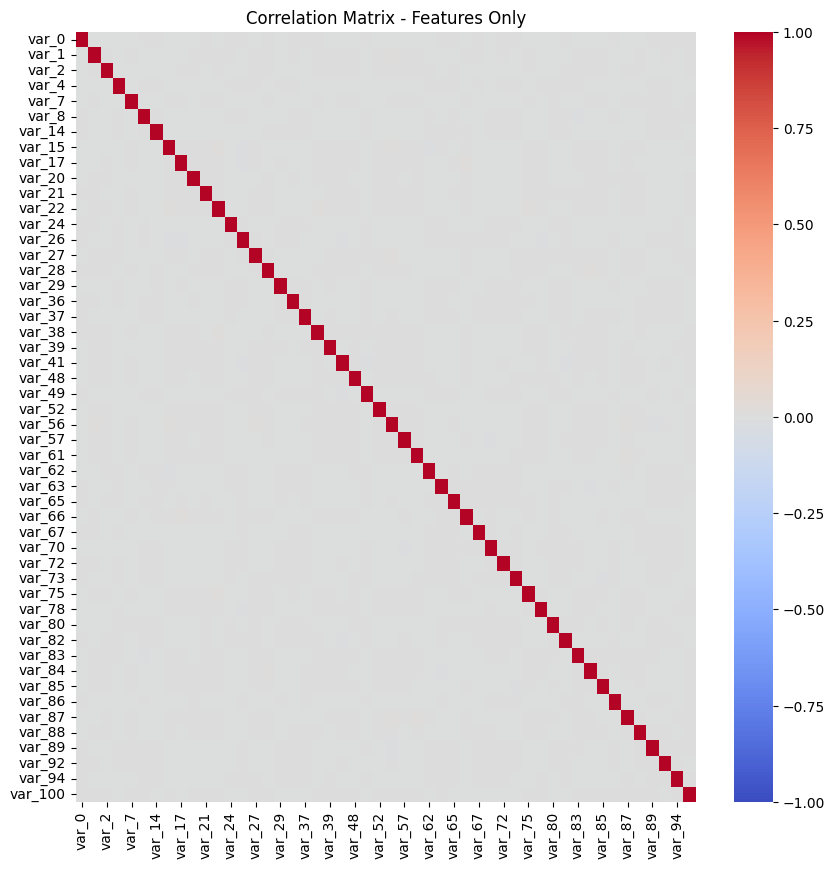

In [ ]:
# Calculate a correlation matrix (features only)
transaction_df_features_only = transaction_df_target_clean[feature_cols]
feature_corr = transaction_df_features_only.corr()

plt.figure(figsize=(10, 10))
sns.heatmap(feature_corr,
            annot=False,
            cmap='coolwarm',  # blue = negative, red = positive
            center=0,         # white/gray = no correlation
            vmin=-1, vmax=1)  # full correlation range
plt.title('Correlation Matrix - Features Only')
plt.show()

#output- correlation between features are near 0
#look independent, 2nd GNB assumption


In [ ]:
# Create two data frames

# no transaction (target= 0)
transaction_df_no_success= transaction_df_target_clean[transaction_df_target_clean['target'] == 0].copy()

# successful transaction (target= 1)
transaction_df_successful= transaction_df_target_clean[transaction_df_target_clean['target'] == 1].copy()


print(type(transaction_df_successful))
print(type(transaction_df_no_success))

print(transaction_df_successful.shape)
print(transaction_df_no_success.shape)


<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.frame.DataFrame'>
(18040, 51)
(161960, 51)


## Data Processing

### Single Cross-validation

In [ ]:
# Split data from into target and features
target =transaction_df_target_clean['target'].copy()
features= transaction_df_target_clean [feature_cols].copy()



In [ ]:
# Train test split
x_train, x_test, y_train, y_test = train_test_split( features, target, test_size=0.25, random_state=42)

In [ ]:
# verify shape of each data set from Train test split
for i in (x_train, x_test,y_train,y_test):
  print(i.shape)
  print(type(i))

(135000, 50)
<class 'pandas.core.frame.DataFrame'>
(45000, 50)
<class 'pandas.core.frame.DataFrame'>
(135000,)
<class 'pandas.core.series.Series'>
(45000,)
<class 'pandas.core.series.Series'>


### Model

In [ ]:
# Create an empty GNB model
modelGNB= GaussianNB()

### Fit

In [ ]:
# Train ( fit ) the model
modelGNB.fit(x_train,y_train)

GaussianNB()

### Prediction

In [ ]:
# Make prediction using the model
pred_result= modelGNB.predict(x_test)

### Performance

In [ ]:
# Calculate the accuracy
accuracy=metrics.accuracy_score(y_test,pred_result)
accuracy*100

91.03999999999999

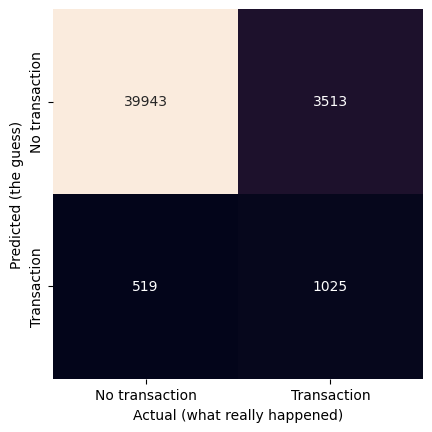

In [ ]:
# Display a confusion matrix
mat = metrics.confusion_matrix(y_test,pred_result)
names = ['No transaction', 'Transaction']
sns.heatmap(mat.T,
    square=True,
    annot=True,
    fmt='d',
    cbar=False,
    xticklabels=names,  #names start left to right
    yticklabels=names,  #names start from top to bottom
)

plt.xlabel('Actual (what really happened)')
plt.ylabel('Predicted (the guess)') ;

In [ ]:
#Classification report
print(metrics.classification_report(y_test, pred_result,zero_division=0 ))


              precision    recall  f1-score   support

         0.0       0.92      0.99      0.95     40462
         1.0       0.66      0.23      0.34      4538

    accuracy                           0.91     45000
   macro avg       0.79      0.61      0.64     45000
weighted avg       0.89      0.91      0.89     45000



### Communication of Results

The target show no transaction (‘0’) or  successful transaction (‘1’).

**Accuracy:** 91%


**Confusion matrix:**

 - 39,943: guessed no transaction, actually no transaction → right
  
 - 3513: guessed no transaction, actually successfull transaction → wrong

 - 519: guessed sucessful transaction, actually no transaction -> wrong

 - 1,025: guess sucessful transaction, actually transaction ->right
  
**Classification report:**
  
  - Recall for successfull transaction: 0.23
    - The model found 1025 out 4538 successfull transaction.

  - Precision for successfull transaction: 0.66
    - The model said successfull transaction 1544 times, right 1025 times

  - 90% is just for the no transaction customer.

**Takeaway:** The 91% accuracy mostly comes from the no-transaction customers. The model guesses "no transaction" for most customers and misses about 3 out of 4 buyers.



### Multiple Cross Validation

In [ ]:
# Multiple cross-validation loop
n= 100
results= np.zeros(n)

for i in range(n):
  x_train, x_test, y_train, y_test= train_test_split(features,target,test_size=0.25, random_state=i)
  modelGNB = GaussianNB()
  modelGNB.fit(x_train,y_train)
  y_pred = modelGNB.predict(x_test)
  results[i]=metrics.accuracy_score(y_test,y_pred)

results


array([0.9114    , 0.91293333, 0.91084444, 0.91148889, 0.91213333,
       0.91157778, 0.91262222, 0.90911111, 0.91177778, 0.91082222,
       0.91166667, 0.91251111, 0.91111111, 0.91255556, 0.91122222,
       0.91095556, 0.91313333, 0.91093333, 0.91071111, 0.91      ,
       0.91088889, 0.91102222, 0.91284444, 0.91142222, 0.91133333,
       0.91011111, 0.91471111, 0.91206667, 0.91066667, 0.91144444,
       0.91242222, 0.90971111, 0.91331111, 0.91126667, 0.91215556,
       0.91024444, 0.91191111, 0.91215556, 0.91273333, 0.91035556,
       0.91311111, 0.91002222, 0.9104    , 0.91262222, 0.91091111,
       0.91237778, 0.91002222, 0.9102    , 0.91155556, 0.91164444,
       0.91026667, 0.91242222, 0.9126    , 0.911     , 0.91153333,
       0.91166667, 0.90993333, 0.91133333, 0.91146667, 0.91095556,
       0.91333333, 0.91126667, 0.91117778, 0.91146667, 0.91128889,
       0.91268889, 0.9114    , 0.91071111, 0.91257778, 0.91104444,
       0.91122222, 0.91311111, 0.91026667, 0.911     , 0.91046

In [ ]:
# Calculate mean of results
results.mean()

np.float64(0.9113124444444444)

**Mean accuracy:** 91.13% across 100 runs. This is almost the same as the Single CV (91.04%). So the single split was a typical result,not luck

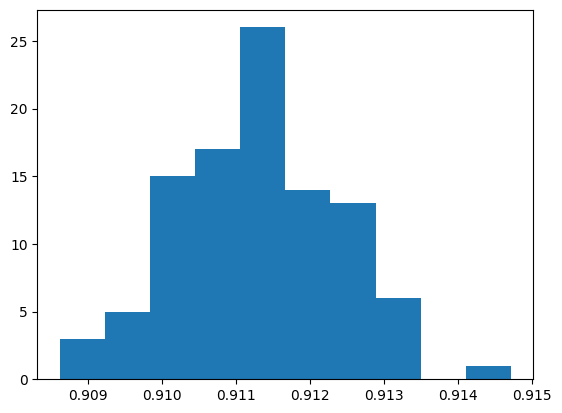

In [ ]:
# Display a histogram of the results
plt.hist(results) ;

**Histogram observation:** The accuracy scores are tightly grouped between about 90.9% and 91.5%. The shape is roughly bell-shaped. The narrow spread means the model gives about the same accuracy no matter how the data is split.

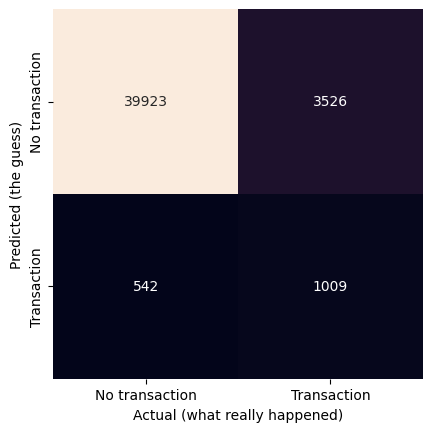

In [ ]:
# display a confusion matrix

mat= metrics.confusion_matrix(y_test,y_pred,)
sns.heatmap( mat.T,
    square=True,
    annot=True,
    fmt = "d",
    cbar = False,
    xticklabels=names,  #names start left to right
    yticklabels=names,  #names start from top to bottom
)
plt.xlabel('Actual (what really happened)')
plt.ylabel('Predicted (the guess)') ;

In [ ]:
# Classification report
print(metrics.classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         0.0       0.92      0.99      0.95     40465
         1.0       0.65      0.22      0.33      4535

    accuracy                           0.91     45000
   macro avg       0.78      0.60      0.64     45000
weighted avg       0.89      0.91      0.89     45000



## Communication of Multiple CV Results

**Classification report** (last of the 100 runs):
- **Recall for successful transaction: 0.22**
  - The model found 1,009 out of 4,535 successful transactions.
- **Precision for successful transaction: 0.65**
  - The model said "successful transaction" 1,551 times and was right 1,009 times.
- No-transaction scores high (precision 0.92, recall 0.99), so the 91% accuracy comes mostly from those customers.

**Takeaway:** The model guessed "no transaction" for most customers and missed about 4 out of 5 buyers.

## Balanced data set

In [ ]:
# Count the transactions databases
number_of_success= len(transaction_df_successful) #len()counts how many rows
print('successful rows:',number_of_success)

number_of_not_successful=len(transaction_df_no_success)
print('No Success rows:',number_of_not_successful)



successful rows: 18040
No Success rows: 161960


In [ ]:
# Create sample of no success row to equal successful rows
transaction_df_no_success_sampled = transaction_df_no_success.sample(n=number_of_success, random_state=42)
print(len(transaction_df_no_success_sampled))

18040


In [ ]:
# Put the two groups together into one table
balance_transaction_df= pd.concat([transaction_df_successful,transaction_df_no_success_sampled])

In [ ]:
# Verify target counts
balance_transaction_df['target'].value_counts()

,count
target,
1.0,18040
0.0,18040


In [ ]:
#split the balance table into target and feature
balance_target = balance_transaction_df['target'].copy()
balance_features = balance_transaction_df[feature_cols].copy()

In [ ]:
# Multiple cross-validation loop
n= 100
balance_results= np.zeros(n)

for i in range(n):
  x_train, x_test, y_train, y_test= train_test_split(balance_features,balance_target,test_size=0.25, random_state=i)
  modelGNB = GaussianNB()
  modelGNB.fit(x_train,y_train)
  y_pred = modelGNB.predict(x_test)
  balance_results[i]=metrics.accuracy_score(y_test,y_pred)

balance_results

array([0.75110865, 0.75643016, 0.75487805, 0.754102  , 0.75166297,
       0.74833703, 0.75587583, 0.75709534, 0.75909091, 0.75443459,
       0.75221729, 0.75432373, 0.75532151, 0.75011086, 0.75720621,
       0.75321508, 0.75421286, 0.75365854, 0.75909091, 0.76042129,
       0.754102  , 0.75576497, 0.75521064, 0.75033259, 0.75177384,
       0.75521064, 0.75144124, 0.75388027, 0.75365854, 0.75321508,
       0.76141907, 0.74778271, 0.7537694 , 0.74889135, 0.75022173,
       0.75742794, 0.75720621, 0.75764967, 0.745898  , 0.75033259,
       0.75177384, 0.75554324, 0.75631929, 0.76064302, 0.75254989,
       0.75388027, 0.75532151, 0.75022173, 0.75365854, 0.75831486,
       0.74944568, 0.74545455, 0.75764967, 0.75310421, 0.74944568,
       0.75121951, 0.75820399, 0.75543237, 0.75288248, 0.75232816,
       0.75731707, 0.75144124, 0.75742794, 0.75144124, 0.75066519,
       0.75299335, 0.75088692, 0.75864745, 0.7597561 , 0.74911308,
       0.75875831, 0.75210643, 0.7575388 , 0.7559867 , 0.75077

In [ ]:
# Calculate mean of balance results
balance_results.mean()

np.float64(0.7540343680709534)

**Mean accuracy (balanced data):** 75.4% across 100 runs, lower than the 91.1% on the whole data.

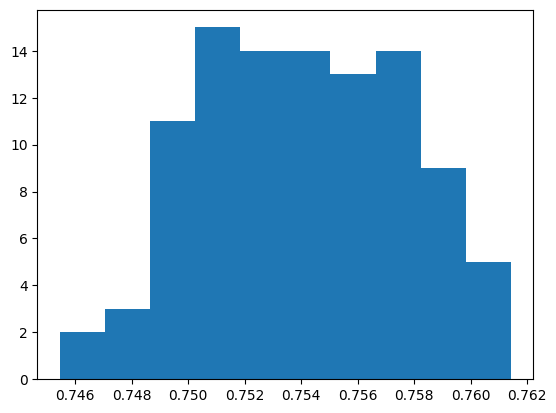

In [ ]:
# Plot a histogram
plt.hist(balance_results) ;

#### Histogram observation

- Most of the accuracy score is between 74%-76.5%, the accuracy score look a little wider than the whole data histogram because the balanced test set is smaller

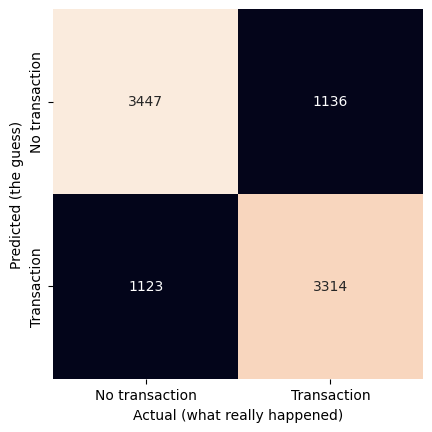

In [ ]:
# display a confusion matrix

mat= metrics.confusion_matrix(y_test,y_pred,)
sns.heatmap( mat.T,
    square=True,
    annot=True,
    fmt = "d",
    cbar = False,
    xticklabels=names,  #names start left to right
    yticklabels=names,  #names start from top to bottom
)
plt.xlabel('Actual (what really happened)')
plt.ylabel('Predicted (the guess)') ;

In [ ]:
# Classification report
print(metrics.classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         0.0       0.75      0.75      0.75      4570
         1.0       0.75      0.74      0.75      4450

    accuracy                           0.75      9020
   macro avg       0.75      0.75      0.75      9020
weighted avg       0.75      0.75      0.75      9020



## Communication of Balanced Data Results

**Classification report** (last of the 100 runs):
- **Recall for successful transaction: 0.74**
  - The model found 3314 out of 4,450 successful transactions.
- **Precision for successful transaction: 0.75**
  - The model said successful transaction 4437 times and was right 3314 times.
- Both classes now score about the same (around 0.75), so the macro and weighted averages match.

**Takeaway:** The model now finds 3 out of 4 buyers, instead of 1 out of 4 with the whole data.

## Data Visualization

In [ ]:
# Model 1: Whole data
x_train, x_test, y_train, y_test_whole = train_test_split(features, target, test_size=0.25, random_state=42)
model_whole = GaussianNB()
model_whole.fit(x_train, y_train)
y_pred_whole = model_whole.predict(x_test)


#Model 2: Balance data [cell 63]
x_train, x_test, y_train, y_test_balance= train_test_split(balance_features,balance_target,test_size=0.25, random_state=42)
modelGNB = GaussianNB()
modelGNB.fit(x_train,y_train)
y_pred_balance = modelGNB.predict(x_test)

In [ ]:
print(results.mean())
print(balance_results.mean())

0.9113124444444444
0.7540343680709534


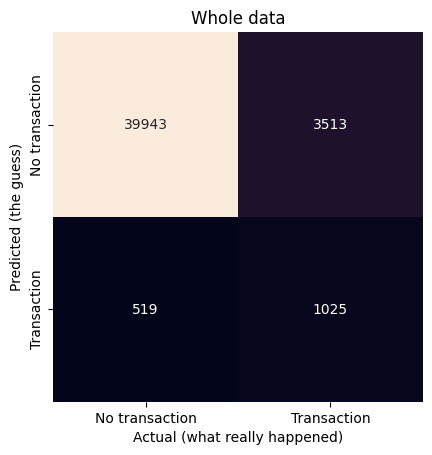

In [ ]:
# Display a confusion matrix (Whole data)

mat = metrics.confusion_matrix(y_test_whole, y_pred_whole)
sns.heatmap(mat.T,
            square=True,
            annot=True,
            fmt='d',
            cbar=False,
            xticklabels=names,
            yticklabels=names)

plt.title('Whole data')
plt.xlabel('Actual (what really happened)')
plt.ylabel('Predicted (the guess)')
plt.show()

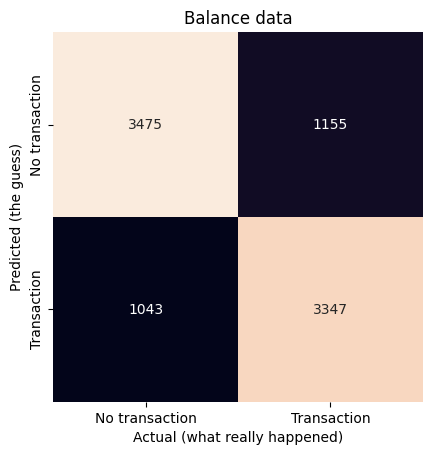

In [ ]:
# Display a confusion matrix (Balance data)

mat = metrics.confusion_matrix(y_test_balance, y_pred_balance)
sns.heatmap(mat.T,
            square=True,
            annot=True,
            fmt='d',
            cbar=False,
            xticklabels=names,
            yticklabels=names)

plt.title('Balance data')
plt.xlabel('Actual (what really happened)')
plt.ylabel('Predicted (the guess)')
plt.show()

In [ ]:
#Classification report (whole data )
print(metrics.classification_report(y_test_whole, y_pred_whole,))

              precision    recall  f1-score   support

         0.0       0.92      0.99      0.95     40462
         1.0       0.66      0.23      0.34      4538

    accuracy                           0.91     45000
   macro avg       0.79      0.61      0.64     45000
weighted avg       0.89      0.91      0.89     45000



In [ ]:
#Classification report (Balance data )
print(metrics.classification_report(y_test_balance, y_pred_balance,))

              precision    recall  f1-score   support

         0.0       0.75      0.77      0.76      4518
         1.0       0.76      0.74      0.75      4502

    accuracy                           0.76      9020
   macro avg       0.76      0.76      0.76      9020
weighted avg       0.76      0.76      0.76      9020



# Communication of Results

|   | Whole data | Balanced data|
|---|---|---|
| Average accuracy (100 runs)| 91% | 76%|
| Recall:  | 0.23 | 0.74|
|Precision: |0.66|0.76


### whole data
  - had a higher accuracy percentage because it guess no transaction majority of the time and
  - lower recall because it did not catch customer who made a transaction
  - lower precision it did not guess right transaction made

### Balanced data
  - had a lower accuracy percentage because it guess a higher amount of success transaction
  - higher recall because it did catch customer who made a transaction
  - higher precision it guess right the transaction made

### Conclusion
  - Use the Balance data because it solve the business problem of predict when a transaction will be made successful.
  - The Whole data model fail at locating successful transaction.
